1. **Loading dataset**

In [1]:
#importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#exporting data
df = pd.read_csv("retail_sales_dataset.csv")

print(df.head())
print(df.shape)
print(df.info())

   Transaction ID        Date Customer ID  Gender  Age Product Category  \
0               1  2023-11-24     CUST001    Male   34           Beauty   
1               2  2023-02-27     CUST002  Female   26         Clothing   
2               3  2023-01-13     CUST003    Male   50      Electronics   
3               4  2023-05-21     CUST004    Male   37         Clothing   
4               5  2023-05-06     CUST005    Male   30           Beauty   

   Quantity  Price per Unit  Total Amount  
0         3              50           150  
1         2             500          1000  
2         1              30            30  
3         1             500           500  
4         2              50           100  
(1000, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-

2. **Understanding the dataset**

In [2]:

# Displaying first five rows
display(df.head())

#Checking the number of rows and columns
print("Dataset shape:", df.shape)

# Checking column names and data types
df.info()

# Checking missing values
print("\nMissing values:")
print(df.isnull().sum())

#Checking duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


Dataset shape: (1000, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB

Missing values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate rows: 0


3. **Data Quality**

In [3]:
#checking data types
print("\nData types:")
print(df.dtypes)

# Checking for invalid or unusual values
print("\nNumerical summary:")
display(df.describe())


Data types:
Transaction ID       int64
Date                object
Customer ID         object
Gender              object
Age                  int64
Product Category    object
Quantity             int64
Price per Unit       int64
Total Amount         int64
dtype: object

Numerical summary:


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


4. **Statistics**



In [4]:

#important numerical columns
columns = ["Age", "Quantity", "Price per Unit", "Total Amount"]

# Calculating mean
print("MEAN")
display(df[columns].mean())

# Calculating median
print("MEDIAN")
display(df[columns].median())

# Calculating mode
print("MODE")
display(df[columns].mode().iloc[0])

# Calculating standard deviation
print("STANDARD DEVIATION")
display(df[columns].std())


MEAN


Age                41.392
Quantity            2.514
Price per Unit    179.890
Total Amount      456.000
dtype: float64

MEDIAN


Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64

MODE


Age               43.0
Quantity           4.0
Price per Unit    50.0
Total Amount      50.0
Name: 0, dtype: float64

STANDARD DEVIATION


Age                13.681430
Quantity            1.132734
Price per Unit    189.681356
Total Amount      559.997632
dtype: float64

**5. Monthly sales trend**

##### 5.1 Preparing the monthly sales data

In [5]:
# Converting Date column into datetime format
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Checking the conversion
print(df["Date"].dtype)
print("Invalid dates:", df["Date"].isna().sum())


datetime64[ns]
Invalid dates: 0


In [6]:
#Extracting year and month from the Date column
df["YearMonth"] = df["Date"].dt.to_period("M")

#Calculating total sales for each month
monthly_sales = df.groupby("YearMonth")["Total Amount"].sum()

#Display monthly sales
display(monthly_sales)


YearMonth
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64

In [7]:
#Extracting year and month
df["YearMonth"] = df["Date"].dt.to_period("M")

#Calculating total sales for each month
monthly_sales = df.groupby("YearMonth")["Total Amount"].sum()

display(monthly_sales)


YearMonth
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64

##### 5.2 Creating line chart


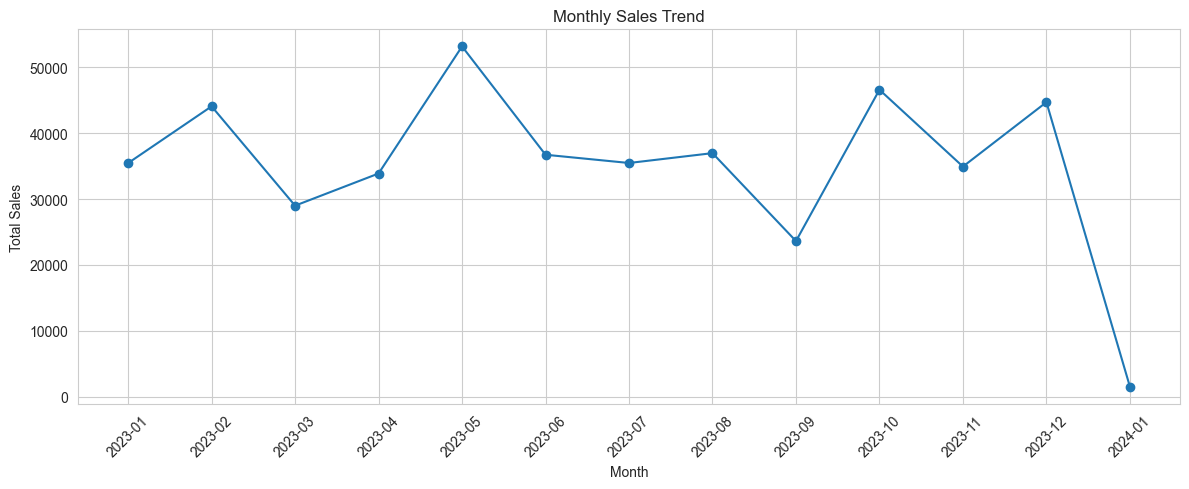

In [8]:
df["YearMonth"] = df["Date"].dt.to_period("M")
monthly_sales = df.groupby("YearMonth")["Total Amount"].sum()

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index.astype(str), monthly_sales.values, marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


**6. Quartely sales**

##### 6.1. Calculating quartely sales


In [9]:
# Extracting the quarter from each transaction date
df["Quarter"] = df["Date"].dt.to_period("Q")

# Calculating total sales for each quarter
quarterly_sales = df.groupby("Quarter")["Total Amount"].sum()

# Displaying the results
display(quarterly_sales)


Quarter
2023Q1    108500
2023Q2    123735
2023Q3     96045
2023Q4    126190
2024Q1      1530
Freq: Q-DEC, Name: Total Amount, dtype: int64

##### 6.2. Bar Chart

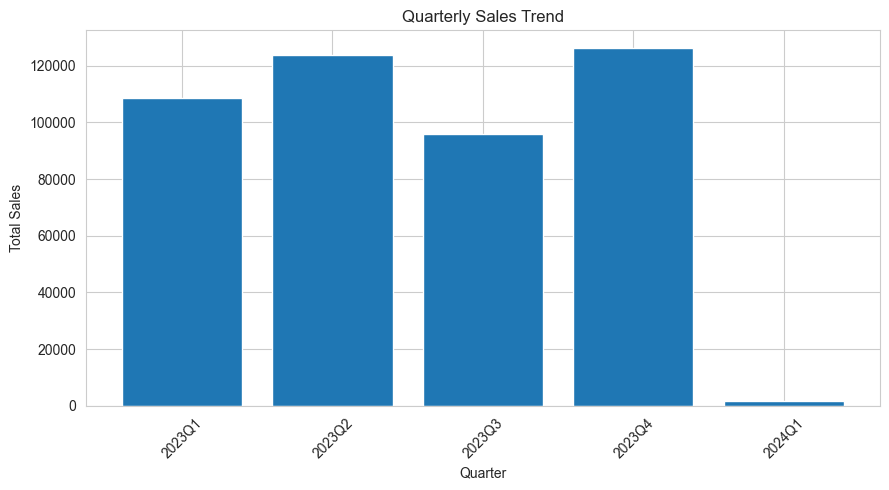

In [10]:
plt.figure(figsize=(9, 5))

plt.bar(quarterly_sales.index.astype(str), quarterly_sales.values)

plt.title("Quarterly Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**7. Age and Gender Analysis**

##### 7.1. Customers by Gender

In [11]:
#Counting transactions by gender
gender_counts = df["Gender"].value_counts()

print("Transactions by Gender:")
display(gender_counts)


Transactions by Gender:


Gender
Female    510
Male      490
Name: count, dtype: int64

##### 7.2. Bar Chart

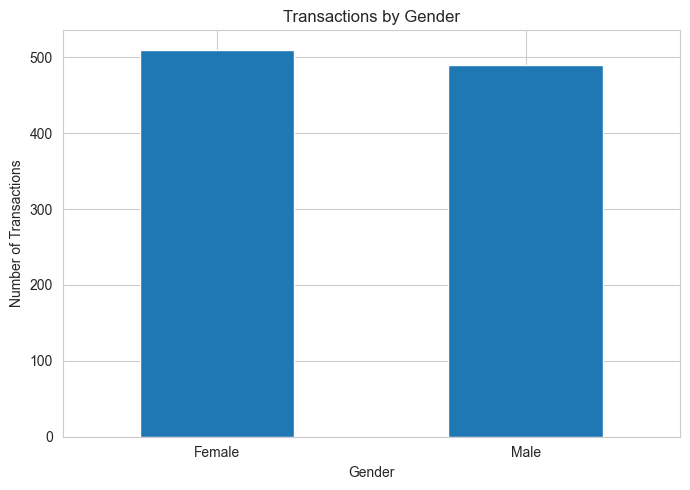

In [12]:
plt.figure(figsize=(7, 5))

gender_counts.plot(kind="bar")

plt.title("Transactions by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


##### 7.3. Customers by age (Bar chart)

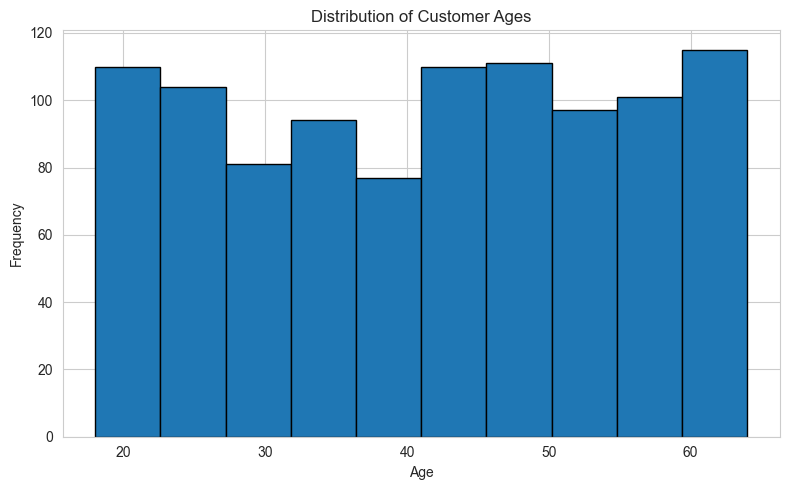

In [13]:
plt.figure(figsize=(8, 5))

plt.hist(df["Age"], bins=10, edgecolor="black")

plt.title("Distribution of Customer Ages")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


**8. Top 10 Products**

##### 8.1. Top 10 transaction by sales



In [14]:
#Sorting transactions by total amount
top_10_sales = df.nlargest(10, "Total Amount")

display(top_10_sales[
    ["Transaction ID", "Product Category", "Quantity", "Total Amount"]
])

,Transaction ID,Product Category,Quantity,Total Amount
14,15,Electronics,4,2000
64,65,Electronics,4,2000
71,72,Electronics,4,2000
73,74,Beauty,4,2000
88,89,Electronics,4,2000
92,93,Beauty,4,2000
108,109,Electronics,4,2000
117,118,Electronics,4,2000
123,124,Clothing,4,2000
138,139,Beauty,4,2000


8.2. Revenue by category(Bar chart)

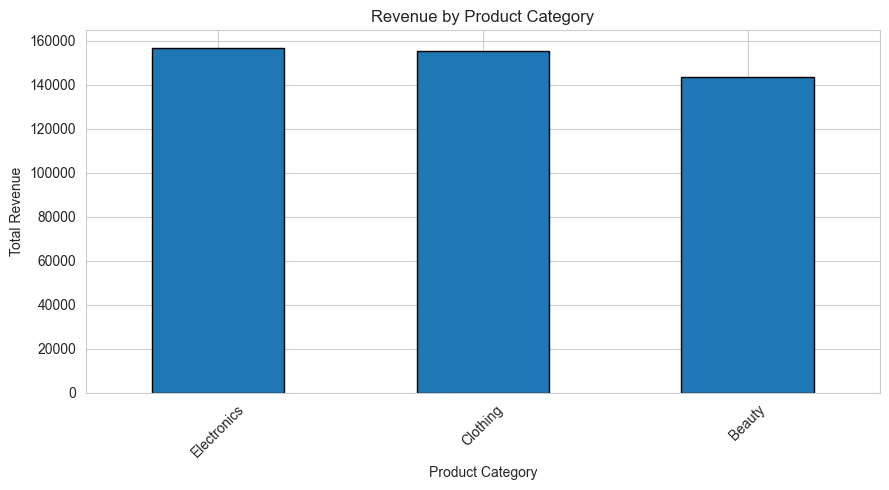

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64

In [15]:
category_revenue = df.groupby("Product Category")["Total Amount"].sum()
category_revenue = category_revenue.sort_values(ascending=False)

plt.figure(figsize=(9, 5))
category_revenue.plot(kind="bar", edgecolor="black")

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(category_revenue)


**9. Correlation Heatmap**

##### 9.1. Calculating

In [16]:
# Selecting numerical columns
numeric_data = df[["Age", "Quantity", "Price per Unit", "Total Amount"]]

# Calculating correlation matrix
correlation_matrix = numeric_data.corr()

display(correlation_matrix)


,Age,Quantity,Price per Unit,Total Amount
Age,1.000000,-0.023737,-0.038423,-0.060568
Quantity,-0.023737,1.000000,0.017501,0.373707
Price per Unit,-0.038423,0.017501,1.000000,0.851925
Total Amount,-0.060568,0.373707,0.851925,1.000000


##### 9.2. Heatmap

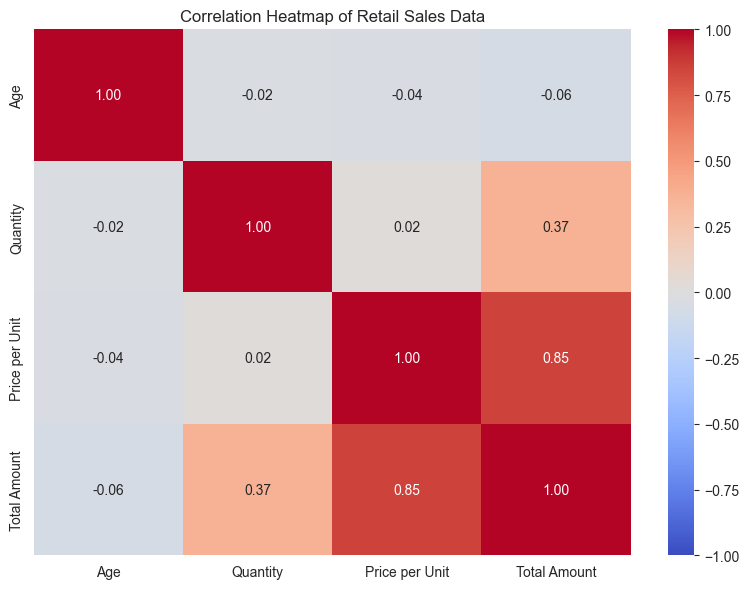

In [17]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Retail Sales Data")
plt.tight_layout()
plt.show()


**10. One more Visualization**

##### 10.1. Histogram


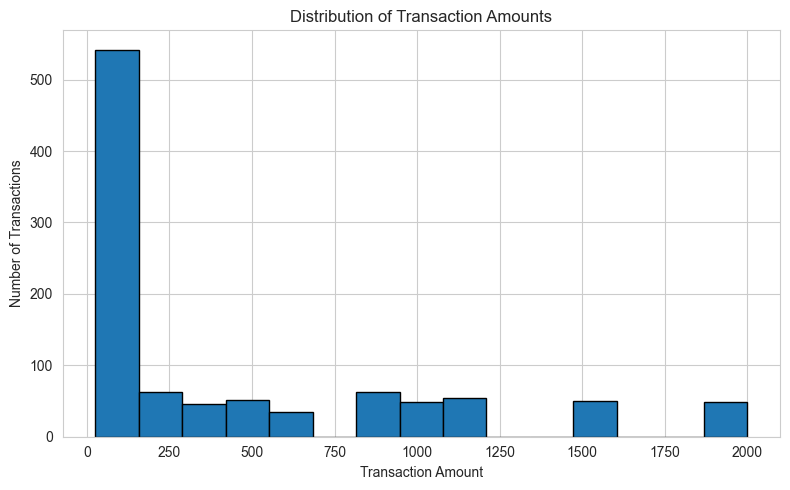

In [18]:
plt.figure(figsize=(8, 5))

plt.hist(df["Total Amount"], bins=15, edgecolor="black")

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()


### **Observation:**

# Main Findings and Business Recommendations

## Main Findings

1. **Trends in Monthly Sales:** The chart demonstrates how the sales revenue varies over time. It is necessary to determine the month of maximum and minimum sales.

2. **Trends in Quarterly Sales:** This type of analysis allows comparing revenue during three months periods and determining stronger and weaker quarters.

3. **Demographic Information of Customers:** The gender chart demonstrates comparison of transactions made by men and women. The age histogram shows how old the customers are.

4. **Performance of Different Product Categories:** It is necessary to use the category revenue chart to determine categories with maximum and minimum revenue.

5. **Correlation Analysis:** The heatmap is needed for analyzing relationships between the numerical variables such as age, quantity, price per unit and total amount.

6. **Distribution of Transaction Amounts:** The histogram demonstrates the distribution of transaction amounts in the dataset.

## Business Recommendations

1. **Sales Planning Optimization:** Analyzing the sales trends monthly and quarterly is useful when planning promotions and purchasing inventory for periods of low sales.

2. **Customers Segmentation:** It is possible to use demographic information to target certain marketing campaigns at particular customers but not to make assumptions about each customer individually.

3. **Product Category Revenue Review:** Reasons for difference in revenues from different categories must be reviewed.